# Week 7 — Prescriptive Analytics
### *What should we do?* From predictions to decisions under constraints
**SENG 42293 Big Data Analytics · LO3**

Descriptive analytics says what happened, predictive says what will happen. **Prescriptive analytics recommends an action**: it combines (1) an objective, (2) decision variables, (3) constraints, and (4) a model of how the world responds.

**In this notebook (travel-review platform):**
1. **Optimisation:** which hotels should we feature in a campaign under a budget? (integer programming)
2. **What-if / sensitivity:** how does the answer change with the budget? what is the value of one more unit of budget?
3. **Simulation under uncertainty:** is the "optimal" plan still good when our estimates are wrong?
4. **Decision under risk:** the classic *overbooking* problem solved two ways (formula and Monte Carlo)

> **Important:** the uplift numbers below come from a transparent *assumed* model, not from real campaign data. In practice the uplift estimates would come from a predictive model (Week 6) or an A/B test (Week 11). Prescriptive results are only as good as the model feeding them.

In [1]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
ACC, ACCL, CH, GREY = "#8b7355", "#c4b5a0", "#2a2a2a", "#999999"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.prop_cycle": plt.cycler(color=[ACC, "#2a2a2a", ACCL, "#b5651d", "#6b8e8e", GREY]),
                     "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold"})
RES = {}                      # key numbers, reused in the slides and notes
def save(name):
    plt.tight_layout(); plt.savefig(f"figures/{name}.png", dpi=130); plt.show()

In [2]:
from scipy.optimize import milp, LinearConstraint, Bounds, linprog
h = pd.read_csv("data/hotel_stats.csv")
h = h[h.n_reviews >= 30].reset_index(drop=True)
print(len(h), "hotels with >= 30 reviews")
h.head(3)

280 hotels with >= 30 reviews


,hotel_id,hotel_name,city,stars,n_reviews,avg_rating,avg_sentiment,pct_positive,last_review
0,H-1001,Royal Resort 1,Nuwara Eliya,4,55,3.718,0.2466,0.709,2025-06-14
1,H-1005,Lakeview Resort 5,Nuwara Eliya,4,58,3.353,0.1000,0.552,2025-05-09
2,H-1034,Lakeview Inn 34,Nuwara Eliya,4,50,3.750,0.2183,0.580,2025-06-01


## 1. Model the decision problem
**Decision:** for each hotel *i*, `x_i = 1` if we feature it in the campaign, else 0.

**Objective:** maximise expected extra bookings **Σ u_i · x_i**

**Constraints**
* Budget: **Σ c_i · x_i ≤ B**   (featuring a bigger hotel costs more)
* Diversification: at most **5 hotels per city**

**Assumed models** (state your assumptions explicitly!):
* cost per hotel by stars: 2★ = 1.0, 3★ = 1.5, 4★ = 2.5, 5★ = 4.0 (budget units)
* expected extra bookings `u_i = 0.1 · n_reviews · (avg_rating / 5)³` — more reviews proxies demand; good ratings convert better

In [3]:
cost_by_star = {2: 1.0, 3: 1.5, 4: 2.5, 5: 4.0}
h["cost"] = h.stars.map(cost_by_star)
h["uplift"] = 0.1 * h.n_reviews * (h.avg_rating / 5) ** 3
h["ratio"] = h.uplift / h.cost
B, CAP = 25.0, 5
print(h[["cost", "uplift", "ratio"]].describe().round(2))

         cost  uplift   ratio
count  280.00  280.00  280.00
mean     2.19    2.01    1.14
std      1.01    0.79    0.73
min      1.00    0.58    0.15
25%      1.50    1.42    0.62
50%      2.00    1.88    0.94
75%      2.50    2.50    1.49
max      4.00    4.40    4.40


## 2. Three ways to decide
1. **Naive:** feature the top-rated hotels until the budget runs out.
2. **Greedy:** best uplift *per unit cost* first (respecting the city cap).
3. **Optimal:** integer linear programming (MILP).

In [4]:
def city_ok(sel_idx, i): return sum(h.city[j] == h.city[i] for j in sel_idx) < CAP
def greedy(order):
    sel, spent = [], 0.0
    for i in order:
        if spent + h.cost[i] <= B and city_ok(sel, i): sel.append(i); spent += h.cost[i]
    return sel
naive = greedy(h.sort_values("avg_rating", ascending=False).index)
greedy_sel = greedy(h.sort_values("ratio", ascending=False).index)

def solve(B=B, cap=CAP, u=None):
    u = h.uplift.values if u is None else u
    cities = sorted(h.city.unique()); n = len(h)
    A = [h.cost.values] + [(h.city == c).astype(float).values for c in cities]
    ub = [B] + [cap] * len(cities)
    r = milp(c=-u, constraints=LinearConstraint(np.array(A), ub=ub), integrality=np.ones(n), bounds=Bounds(0, 1))
    return [i for i in range(n) if r.x[i] > .5], -r.fun
opt, opt_val = solve()
val = lambda sel: h.uplift[sel].sum()
tab = pd.DataFrame({"hotels chosen": [len(naive), len(greedy_sel), len(opt)], "cost used": [h.cost[s].sum() for s in (naive, greedy_sel, opt)],
                    "expected extra bookings": [val(naive), val(greedy_sel), opt_val]}, index=["naive (top rated)", "greedy (uplift per cost)", "optimal (MILP)"]).round(2)
display(tab)
RES["plans"] = tab.reset_index().rename(columns={"index": "plan"}).to_dict("records")
RES["opt_gain_vs_naive_pct"] = round(100 * (opt_val / val(naive) - 1), 1)
print(f"optimal beats naive by {RES['opt_gain_vs_naive_pct']}%")

,hotels chosen,cost used,expected extra bookings
naive (top rated),14,25.0,44.09
greedy (uplift per cost),21,24.5,69.85
optimal (MILP),21,25.0,70.84


optimal beats naive by 60.7%


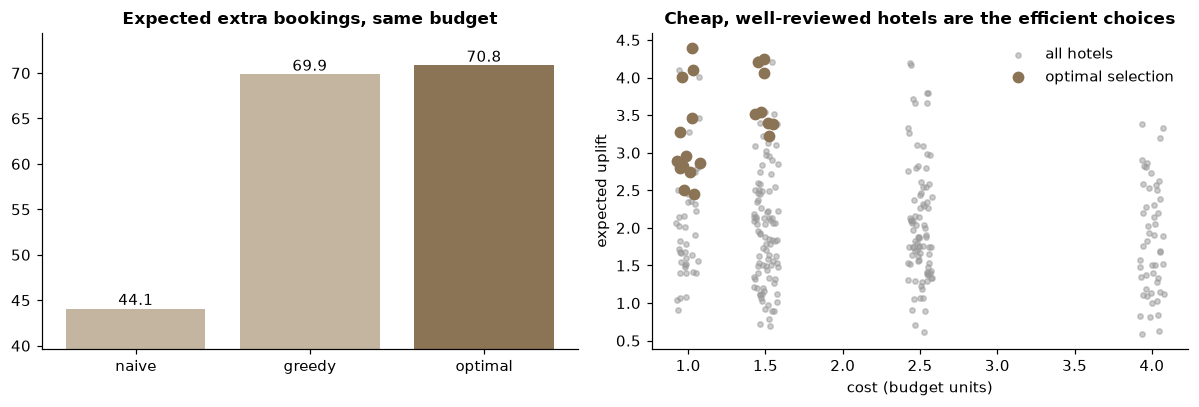

,hotel_name,city,stars,n_reviews,avg_rating,cost,uplift
208,Sunrise Inn 156,Galle,2,72,4.24,1.0,4.40
217,Palm Inn 243,Ella,3,71,4.21,1.5,4.24
268,Palm Residency 86,Galle,3,66,4.30,1.5,4.21
240,Lakeview Resort 158,Galle,2,74,4.11,1.0,4.10
196,Royal Resort 120,Kandy,3,82,3.96,1.5,4.06
3,Hilltop Resort 50,Nuwara Eliya,2,57,4.45,1.0,4.01
22,Sunrise Inn 168,Nuwara Eliya,3,76,3.88,1.5,3.54
41,Palm Lodge 61,Sigiriya,3,76,3.87,1.5,3.52


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
names = ["naive", "greedy", "optimal"]; vals = [val(naive), val(greedy_sel), opt_val]
ax[0].bar(names, vals, color=[ACCL, ACCL, ACC]); ax[0].set_title("Expected extra bookings, same budget"); ax[0].set_ylim(min(vals) * .9)
for i, v in enumerate(vals): ax[0].text(i, v, f"{v:.1f}", ha="center", va="bottom")
ax[1].scatter(h.cost + np.random.default_rng(1).uniform(-.08, .08, len(h)), h.uplift, s=12, color=GREY, alpha=.5, label="all hotels")
ax[1].scatter(h.cost[opt] + np.random.default_rng(2).uniform(-.08, .08, len(opt)), h.uplift[opt], s=45, color=ACC, label="optimal selection")
ax[1].set_xlabel("cost (budget units)"); ax[1].set_ylabel("expected uplift"); ax[1].set_title("Cheap, well-reviewed hotels are the efficient choices"); ax[1].legend(frameon=False)
save("w07_plans")
display(h.loc[opt, ["hotel_name", "city", "stars", "n_reviews", "avg_rating", "cost", "uplift"]].round(2).sort_values("uplift", ascending=False).head(8))

**Why does the naive plan lose?** Ranking by rating alone ignores both *cost* (it buys expensive 4-5 star hotels) and *volume* (a 4.8-star hotel with few reviews adds little demand). The optimiser buys uplift where it is cheapest. *Greedy by ratio* is usually close but not provably optimal (it is a knapsack problem).

## 3. What-if analysis: the value of budget
Solve for many budgets and plot the **efficient frontier**. The slope is the marginal value of one more unit of budget.

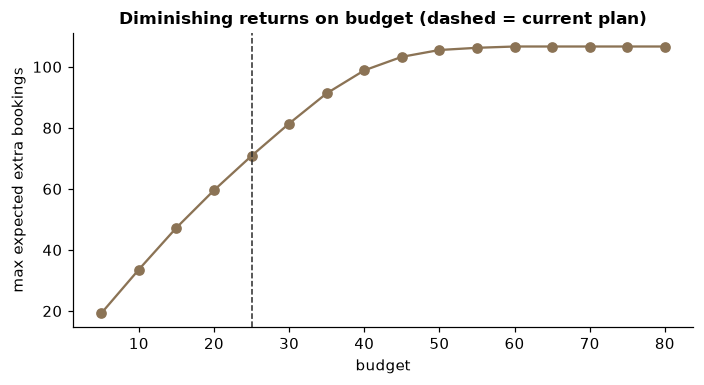

{5: 19.3, 10: 33.6, 15: 47.3, 20: 59.6, 25: 70.8, 30: 81.4, 35: 91.3, 40: 98.8, 45: 103.3, 50: 105.5, 55: 106.2, 60: 106.7, 65: 106.7, 70: 106.7, 75: 106.7, 80: 106.7}


In [6]:
budgets = np.arange(5, 81, 5); frontier = [solve(B=b)[1] for b in budgets]
fig, ax = plt.subplots(figsize=(6.5, 3.6)); ax.plot(budgets, frontier, "o-", color=ACC); ax.axvline(B, color=CH, ls="--", lw=1)
ax.set_xlabel("budget"); ax.set_ylabel("max expected extra bookings"); ax.set_title("Diminishing returns on budget (dashed = current plan)")
save("w07_frontier")
RES["frontier"] = {int(b): round(float(v), 1) for b, v in zip(budgets, frontier)}
print({int(b): round(float(v), 1) for b, v in zip(budgets, frontier)})

In [7]:
# Shadow prices from the LP relaxation (x allowed to be fractional): value of one more unit of each constraint
cities = sorted(h.city.unique()); A = np.array([h.cost.values] + [(h.city == c).astype(float).values for c in cities]); ub = np.array([B] + [CAP] * len(cities))
lp = linprog(-h.uplift.values, A_ub=A, b_ub=ub, bounds=(0, 1), method="highs")
sp = pd.Series(-lp.ineqlin.marginals, index=["budget"] + [f"city cap: {c}" for c in cities]).round(3)
print("LP relaxation value:", round(-lp.fun, 2), "vs integer optimum:", round(opt_val, 2)); display(sp.to_frame("shadow price"))
RES["shadow_budget"] = float(sp["budget"]); RES["lp_value"] = round(float(-lp.fun), 2)

LP relaxation value: 70.93 vs integer optimum: 70.84


,shadow price
budget,2.162
city cap: Colombo,0.000
city cap: Ella,0.000
city cap: Galle,0.189
city cap: Kandy,0.000
city cap: Nuwara Eliya,0.000
city cap: Sigiriya,0.000


The **shadow price** of the budget is the extra bookings gained from one more budget unit. If it is high, asking for more budget is justified; if a city cap has a price of zero, that constraint is not limiting.

## 4. Robustness: simulate the uncertainty
Our uplift estimates are noisy. Suppose each true uplift is the estimate times a random factor (lognormal). Estimates based on **fewer reviews are noisier**: we use a relative spread of 3/sqrt(n_reviews), about 55% at 30 reviews and 32% at 90. Evaluate each plan over 5,000 simulated worlds.

,mean,5th percentile,95th percentile,std
naive,44.14,36.06,53.38,5.25
greedy,69.91,60.87,79.99,5.76
optimal,70.90,61.93,80.72,5.78


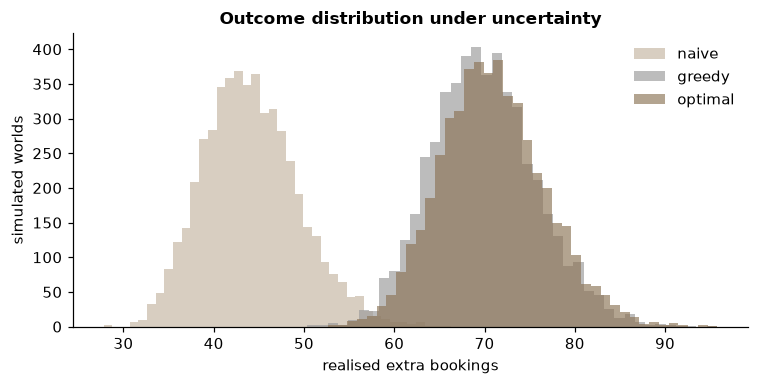

In [8]:
rng = np.random.default_rng(42); S = 5000
cv = 3 / np.sqrt(h.n_reviews.values)                                   # relative uncertainty per hotel
noise = rng.lognormal(mean=-cv**2 / 2, sigma=cv, size=(S, len(h)))      # mean factor exactly 1.0
worlds = noise * h.uplift.values
out = {}
for name, sel in [("naive", naive), ("greedy", greedy_sel), ("optimal", opt)]:
    tot = worlds[:, sel].sum(1); out[name] = tot
summ = pd.DataFrame({k: {"mean": v.mean(), "5th percentile": np.percentile(v, 5), "95th percentile": np.percentile(v, 95), "std": v.std()} for k, v in out.items()}).T.round(2)
display(summ); RES["sim"] = summ.reset_index().rename(columns={"index": "plan"}).to_dict("records")
fig, ax = plt.subplots(figsize=(7, 3.6))
for (k, v), c in zip(out.items(), [ACCL, GREY, ACC]): ax.hist(v, bins=40, alpha=.65, color=c, label=k)
ax.set_xlabel("realised extra bookings"); ax.set_ylabel("simulated worlds"); ax.set_title("Outcome distribution under uncertainty"); ax.legend(frameon=False); save("w07_simulation")

Even the "optimal" plan has a *range* of outcomes. A **risk-averse** planner may prefer a plan with a better 5th percentile. A simple approach is to optimise a penalised objective, **mean - λ·risk**. Hotels whose estimates rest on few reviews carry more risk, so the penalty steers the plan toward well-evidenced hotels.

In [9]:
sd = h.uplift.values * cv                                           # std of each hotel's uplift
rob, _ = solve(u=h.uplift.values - 1.0 * sd)                        # penalise by one standard deviation
rob_tot = worlds[:, rob].sum(1)
cmp = pd.DataFrame({"optimal (mean)": [out["optimal"].mean(), np.percentile(out["optimal"], 5)], "robust (mean - 1 sd)": [rob_tot.mean(), np.percentile(rob_tot, 5)]}, index=["mean", "5th percentile"]).round(2)
display(cmp); RES["robust"] = cmp.to_dict()
print("hotels in both plans:", len(set(opt) & set(rob)), "of", len(opt))

,optimal (mean),robust (mean - 1 sd)
mean,70.90,70.78
5th percentile,61.93,61.82


hotels in both plans: 20 of 21


**Reading the result:** the robust plan is almost identical to the optimal one, and it does *not* improve the 5th percentile. That is a real finding, not a failure: the uncertainty is independent across 21 hotels, so it largely averages out (the total has a standard deviation of about 6 on a mean of about 71). Risk adjustment matters when risks are **concentrated or correlated**, for example if all chosen hotels depend on one holiday season. Always test whether a more complex method actually helps.

## 5. A classic prescriptive problem: overbooking
A hotel has **100 rooms**. Each confirmed booking shows up with probability **0.90**. A room filled earns **100**; each guest we cannot house must be compensated and re-accommodated at a cost of **250**.

*How many bookings N should we accept?*

best N by formula = 109 (expected profit 9640) | best N by simulation = 109


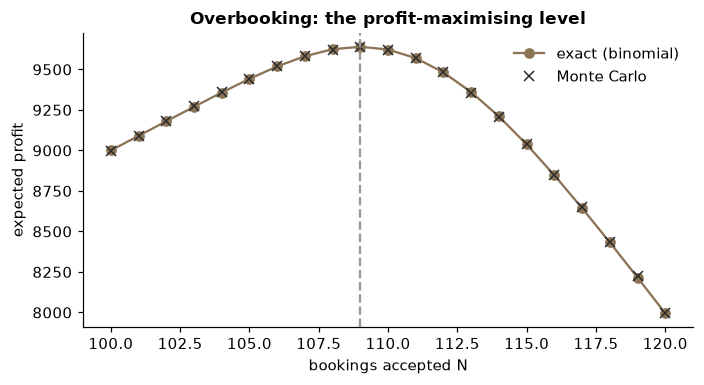

{'best_N': 109, 'profit': 9640, 'profit_no_overbook': 9000, 'gain_pct': np.float64(7.1)}


In [10]:
from scipy.stats import binom
ROOMS, P, REV, WALK = 100, 0.90, 100, 250
Ns = np.arange(100, 121)
def exp_profit(N):
    k = np.arange(N + 1); pmf = binom.pmf(k, N, P)
    return float((pmf * (REV * np.minimum(k, ROOMS) - WALK * np.maximum(k - ROOMS, 0))).sum())
profits = np.array([exp_profit(N) for N in Ns]); bestN = int(Ns[profits.argmax()])
# Monte Carlo check
rng = np.random.default_rng(0); mc = []
for N in Ns:
    shows = rng.binomial(N, P, 20000); mc.append((REV * np.minimum(shows, ROOMS) - WALK * np.maximum(shows - ROOMS, 0)).mean())
print(f"best N by formula = {bestN} (expected profit {profits.max():.0f}) | best N by simulation = {int(Ns[np.argmax(mc)])}")
fig, ax = plt.subplots(figsize=(6.5, 3.6)); ax.plot(Ns, profits, "o-", color=ACC, label="exact (binomial)"); ax.plot(Ns, mc, "x", color=CH, label="Monte Carlo")
ax.axvline(bestN, color=GREY, ls="--"); ax.set_xlabel("bookings accepted N"); ax.set_ylabel("expected profit"); ax.set_title("Overbooking: the profit-maximising level"); ax.legend(frameon=False); save("w07_overbooking")
RES["overbook"] = {"best_N": bestN, "profit": round(float(profits.max())), "profit_no_overbook": round(exp_profit(100)), "gain_pct": round(100 * (profits.max() / exp_profit(100) - 1), 1)}
print(RES["overbook"])

**Marginal reasoning:** accept one more booking while *P(that guest shows and a room is free) × revenue* exceeds *P(that guest shows and no room is free) × walk cost*. This is the **newsvendor** logic that appears in inventory, capacity and pricing problems.

## 6. Connecting the pieces
| Layer | Question | Tool | In this notebook |
|---|---|---|---|
| Descriptive | what happened? | aggregation | review counts, ratings |
| Predictive | what will happen? | model | uplift (assumed here; learn it in practice) |
| **Prescriptive** | **what should we do?** | **optimisation + simulation** | **MILP, frontier, Monte Carlo** |

**At scale:** MILP solvers do not distribute easily. The common big-data pattern is to *aggregate and filter in Spark*, then solve the (small) optimisation on one machine. Large problems use decomposition or heuristics.

## 7. Exercises
1. Change the city cap from 5 to 1 and 10. How does the optimum change, and what does the shadow price tell you?
2. Add a constraint: at least one hotel in **every** city. What does it cost?
3. Replace the uplift model with `0.1 * n_reviews * (avg_sentiment + 1)`. Does the optimal set change much? What does that say about model risk?
4. Overbooking: set the walk cost to 100 and to 500. How does the best N move, and why?
5. Write three sentences recommending a plan to a marketing manager, including the risk.

In [11]:
json.dump(RES, open("results/w07.json", "w"), indent=1); print(RES["overbook"], RES["opt_gain_vs_naive_pct"])

{'best_N': 109, 'profit': 9640, 'profit_no_overbook': 9000, 'gain_pct': np.float64(7.1)} 60.7
